Text(0, 0.5, 'Y-axis')

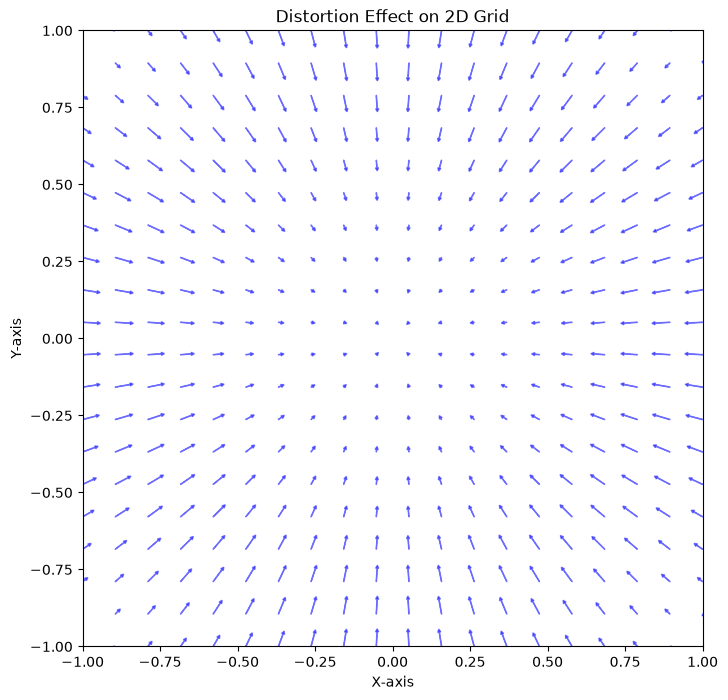

In [4]:
# generate a 2d space grid on [0, 1] x [0, 1]
import numpy as np

grid = np.linspace(-1, 1, 20)
grid = np.array(np.meshgrid(grid, grid)).T.reshape(-1, 2)
distortion_params = [
                -0.18026530920408695,
                0.17271900132935819,
                -0.04013999301015151
            ]

def distort_points(points, distortion_params):
    k1, k2, k3 = distortion_params
    x = points[:, 0]
    y = points[:, 1]
    r2 = x**2 + y**2
    radial_distortion = 1 + k1 * r2 + k2 * r2**2 + k3 * r2**3
    x_distorted = x * radial_distortion
    y_distorted = y * radial_distortion
    return np.stack([x_distorted, y_distorted], axis=1)

import matplotlib.pyplot as plt

distorted_grid = distort_points(grid, distortion_params)

plt.figure(figsize=(8, 8))
# plot arrow from grid to distorted_grid
for i in range(grid.shape[0]):
    plt.arrow(grid[i, 0], grid[i, 1], distorted_grid[i, 0] - grid[i, 0], distorted_grid[i, 1] - grid[i, 1], 
              head_width=0.01, head_length=0.01, fc='blue', ec='blue', alpha=0.5)
#plt.scatter(grid[:, 0], grid[:, 1], color='red', label='Original Grid')
#plt.scatter(distorted_grid[:, 0], distorted_grid[:, 1], color='green', label='Distorted Grid')
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.title('Distortion Effect on 2D Grid')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
